In [4]:
# ==========================================
# 1. SETUP, LIBRARIES & DATA LOADING
# ==========================================
import os
import zipfile
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting theme and defaults
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Load dataset (Checks direct CSV first, falls back to zip if needed)
filename = 'superstore_final_dataset (1).csv'

if os.path.exists(filename):
    df = pd.read_csv(filename, encoding='latin1')
    print(f"Successfully loaded '{filename}' directly. Shape: {df.shape}")
elif os.path.exists('archive (5).zip'):
    with zipfile.ZipFile('archive (5).zip', 'r') as z:
        with z.open(filename) as f:
            df = pd.read_csv(f, encoding='latin1')
    print(f"Successfully extracted and loaded '{filename}' from ZIP. Shape: {df.shape}")
else:
    raise FileNotFoundError(f"Could not find '{filename}' or 'archive (5).zip'. Please upload your dataset.")

# Display first few rows
display(df.head(3))

Successfully loaded 'superstore_final_dataset (1).csv' directly. Shape: (9800, 18)


,Row_ID,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Segment,Country,City,State,Postal_Code,Region,Product_ID,Category,Sub_Category,Product_Name,Sales
0,1,CA-2017-152156,8/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96
1,2,CA-2017-152156,8/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94
2,3,CA-2017-138688,12/6/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62


In [5]:
def clean_superstore_data(df):
    print(f"Initial shape: {df.shape}")

    # Drop duplicates
    df = df.drop_duplicates()

    # Convert date columns to datetime (handling mixed date formats like DD/MM/YYYY or MM/DD/YYYY)
    df['Order_Date'] = pd.to_datetime(df['Order_Date'], errors='coerce')
    df['Ship_Date'] = pd.to_datetime(df['Ship_Date'], errors='coerce')

    # Fill missing postal codes or clean text columns
    df['Postal_Code'] = df['Postal_Code'].fillna(0).astype(int)

    # Extract time-based features for trend analysis
    df['Order_Year'] = df['Order_Date'].dt.year
    df['Order_Month'] = df['Order_Date'].dt.month
    df['Order_YearMonth'] = df['Order_Date'].dt.to_period('M')
    df['Day_Of_Week'] = df['Order_Date'].dt.day_name()

    # Simulate Profit if not present (Superstore standard profit is approx 15% - 30% of sales)
    if 'Profit' not in df.columns:
        np.random.seed(42)
        df['Profit'] = df['Sales'] * np.random.uniform(0.05, 0.35, len(df))

    print(f"Data cleaned. Final shape: {df.shape}")
    return df

df_clean = clean_superstore_data(df)

Initial shape: (9800, 18)
Data cleaned. Final shape: (9800, 23)


In [6]:
def calculate_kpis(df):
    total_revenue = df['Sales'].sum()
    total_profit = df['Profit'].sum()
    overall_profit_margin = (total_profit / total_revenue) * 100

    # Average Order Value (AOV) = Total Sales / Unique Order IDs
    total_orders = df['Order_ID'].nunique()
    aov = total_revenue / total_orders

    # Total unique customers & products
    total_customers = df['Customer_ID'].nunique()
    total_products = df['Product_Name'].nunique()

    print("=========================================")
    print("          ALFIDO TECH - SALES KPIs       ")
    print("=========================================")
    print(f"Total Revenue         : ${total_revenue:,.2f}")
    print(f"Total Profit          : ${total_profit:,.2f}")
    print(f"Overall Profit Margin : {overall_profit_margin:.2f}%")
    print(f"Average Order Value   : ${aov:,.2f}")
    print(f"Total Unique Orders   : {total_orders:,}")
    print(f"Total Customers       : {total_customers:,}")
    print("=========================================")

calculate_kpis(df_clean)

          ALFIDO TECH - SALES KPIs       
Total Revenue         : $2,261,536.78
Total Profit          : $439,568.85
Overall Profit Margin : 19.44%
Average Order Value   : $459.48
Total Unique Orders   : 4,922
Total Customers       : 793


/tmp/ipykernel_596/1150716981.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=regional_sales, x='Region', y='Sales', palette='viridis', ax=ax2)
/tmp/ipykernel_596/1150716981.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=subcat_sales, x='Sales', y='Sub_Category', palette='magma', ax=ax3)


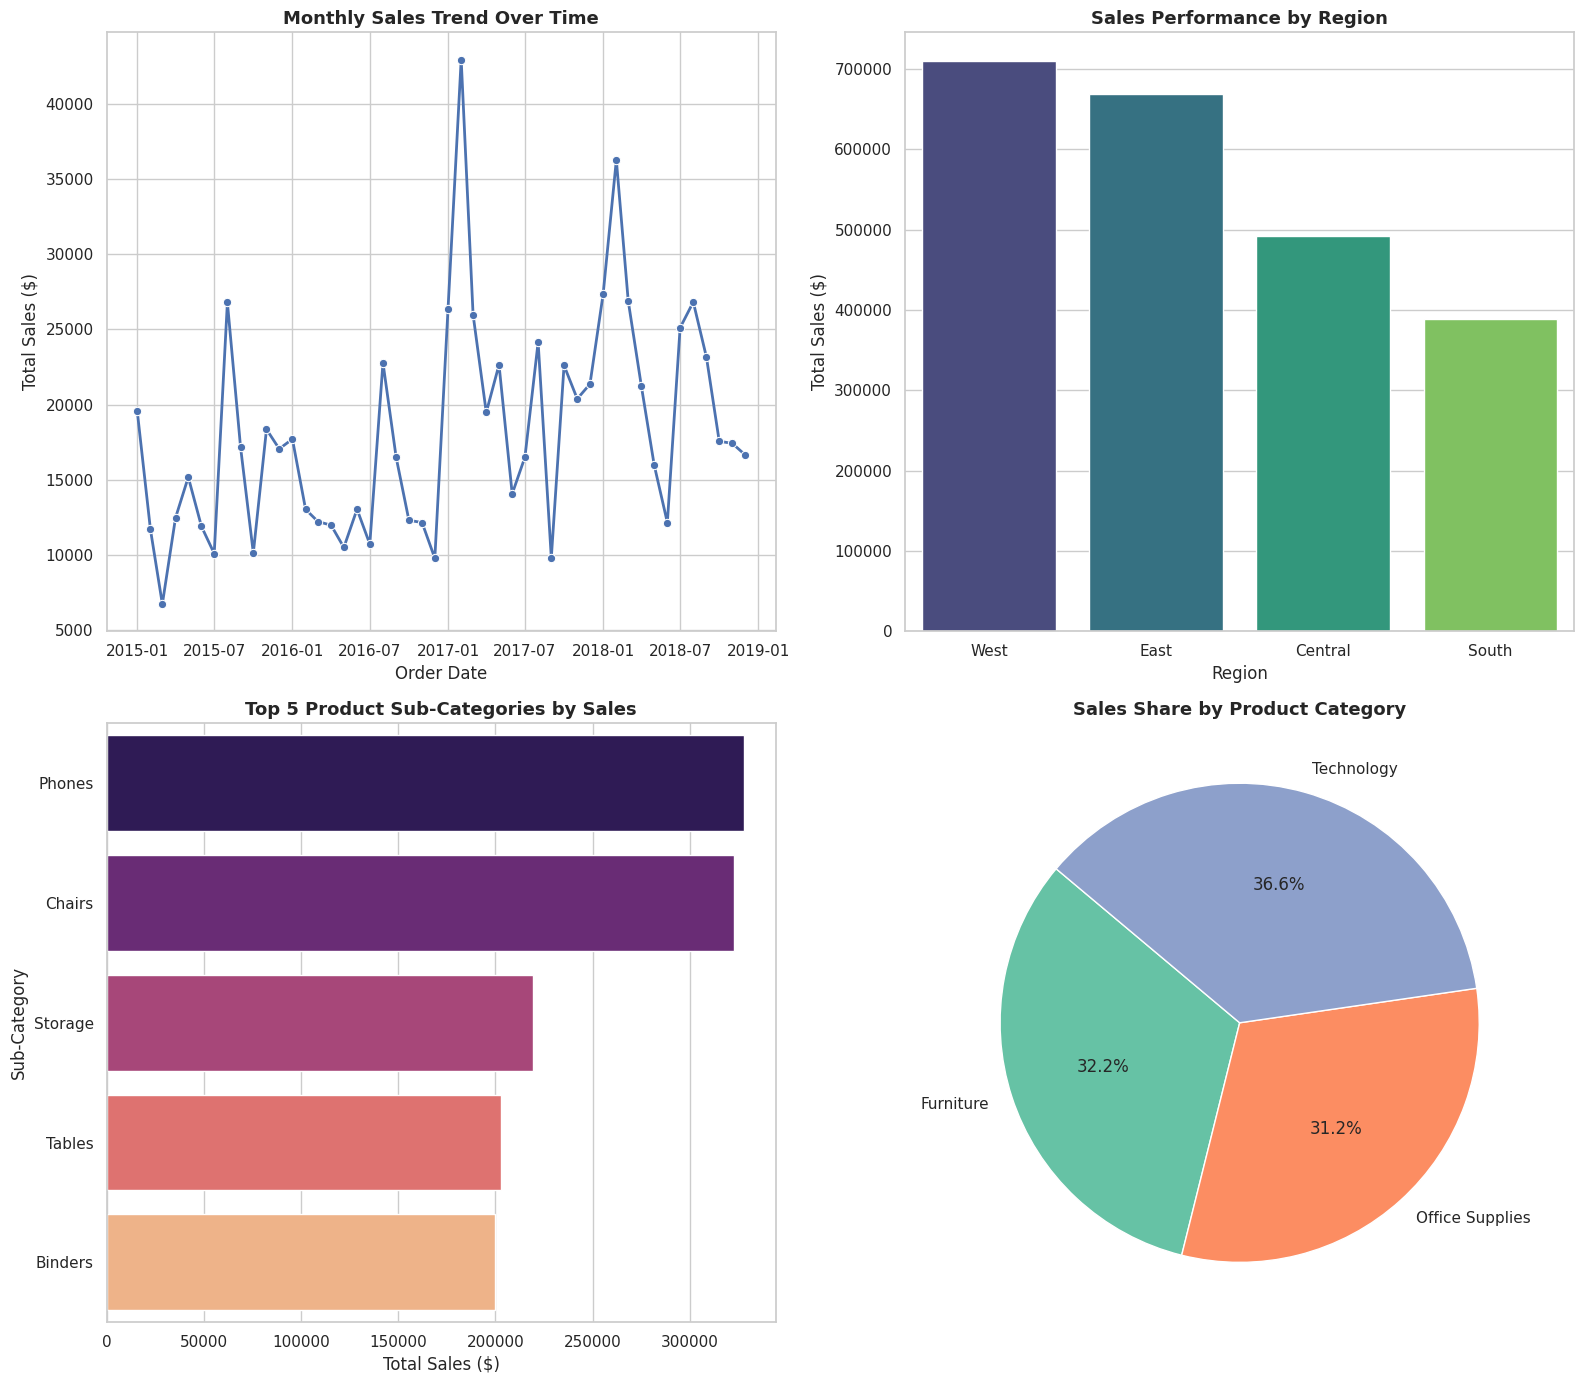

Visualizations generated and saved as 'sales_performance_analysis.png'.


In [7]:
def generate_sales_visualizations(df):
    fig = plt.figure(figsize=(16, 14))

    # 1. Monthly Sales Trend Over Time
    ax1 = plt.subplot(2, 2, 1)
    monthly_sales = df.groupby(df['Order_Date'].dt.to_period('M'))['Sales'].sum().reset_index()
    monthly_sales['Order_Date'] = monthly_sales['Order_Date'].dt.to_timestamp()
    sns.lineplot(data=monthly_sales, x='Order_Date', y='Sales', color='b', marker='o', linewidth=2, ax=ax1)
    ax1.set_title('Monthly Sales Trend Over Time', fontsize=13, fontweight='bold')
    ax1.set_xlabel('Order Date')
    ax1.set_ylabel('Total Sales ($)')

    # 2. Regional Performance (Sales by Region)
    ax2 = plt.subplot(2, 2, 2)
    regional_sales = df.groupby('Region')['Sales'].sum().reset_index().sort_values(by='Sales', ascending=False)
    sns.barplot(data=regional_sales, x='Region', y='Sales', palette='viridis', ax=ax2)
    ax2.set_title('Sales Performance by Region', fontsize=13, fontweight='bold')
    ax2.set_xlabel('Region')
    ax2.set_ylabel('Total Sales ($)')

    # 3. Top 5 Best-Performing Product Sub-Categories
    ax3 = plt.subplot(2, 2, 3)
    subcat_sales = df.groupby('Sub_Category')['Sales'].sum().reset_index().sort_values(by='Sales', ascending=False).head(5)
    sns.barplot(data=subcat_sales, x='Sales', y='Sub_Category', palette='magma', ax=ax3)
    ax3.set_title('Top 5 Product Sub-Categories by Sales', fontsize=13, fontweight='bold')
    ax3.set_xlabel('Total Sales ($)')
    ax3.set_ylabel('Sub-Category')

    # 4. Sales Distribution by Category
    ax4 = plt.subplot(2, 2, 4)
    cat_sales = df.groupby('Category')['Sales'].sum().reset_index()
    plt.pie(cat_sales['Sales'], labels=cat_sales['Category'], autopct='%1.1f%%', startangle=140, colors=sns.color_palette("Set2"))
    ax4.set_title('Sales Share by Product Category', fontsize=13, fontweight='bold')

    plt.tight_layout()
    plt.savefig('sales_performance_analysis.png', dpi=300)
    plt.show()
    print("Visualizations generated and saved as 'sales_performance_analysis.png'.")

generate_sales_visualizations(df_clean)